## Теоретические основы

А. Рекуррентные нейронные сети применяются в основном для анализва временныз последовательностей. Так как используют предыдущие значения.\
Это подойдет для анализа текста, аудио, временных рядов.

В. Примеры формулировки задач:
- «один ко многим» (Р: например, для генерации описания изображений, когда на вход подаются карты признаков изображения, а на выходе получаем его описание (текст), генерация музыки по настроению, подается один вектор (например, жанр или эмоция), на выходе формируется последовательность музыкальных нот)
- «многие ко многим» (Р: например, для перевода текстов, разметка частей речи (последовательность слов на входе, на выходе — последовательность тегов (существительное, глагол) той же длины))
- «многие к одному» (Р: например, для анализа эмоциональной окраски текста (на входе текст, на выходе категории: положительный, нейтральный, отрицательный), прогнозирование отказа двигателя, подается последовательность показаний датчиков за неделю, на выходе — бинарный прогноз)

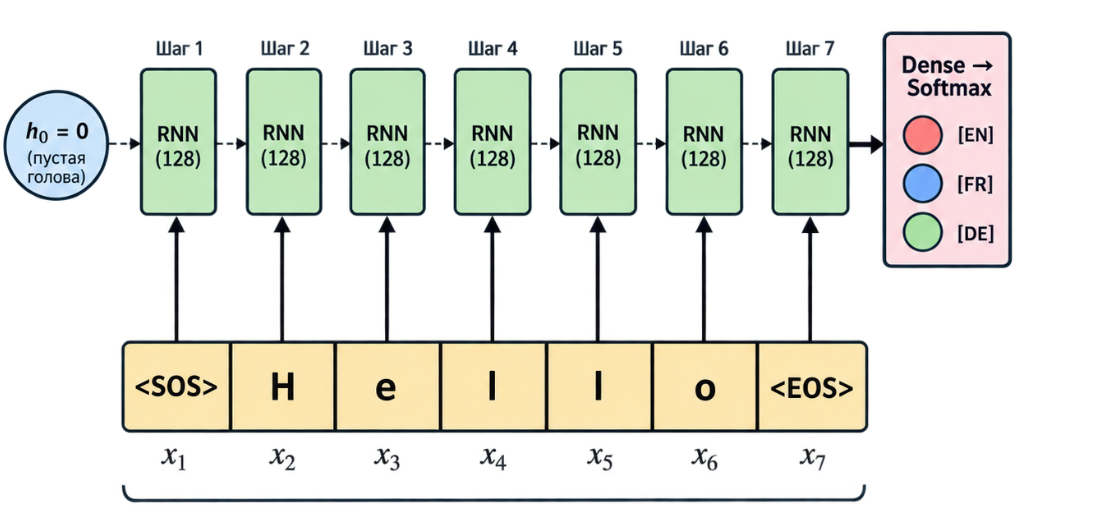

$h_0=0$ — вектор нулей. Это нулевое скрытое состояние (пустая голова). Размерность этого вектора — 128.
\
На каждом шаге блок RNN:
- Принимает текущий вход $x_n$
- Принимает скрытое состояние с предыдущего шага $h_{n-1}$
- Вычисляет новое скрытое состояние по формуле: $h_n = \tanh(W_{hh}h_{n-1} + W_{xh}x_n + b_h)$

Финальный выход
После обработки последнего токена <EOS> получаем финальное скрытое состояние $h_7$
Оно подается на слой:
- Dense (линейный слой)
- Softmax -> превращает три числа в вероятности (сумма = 1)

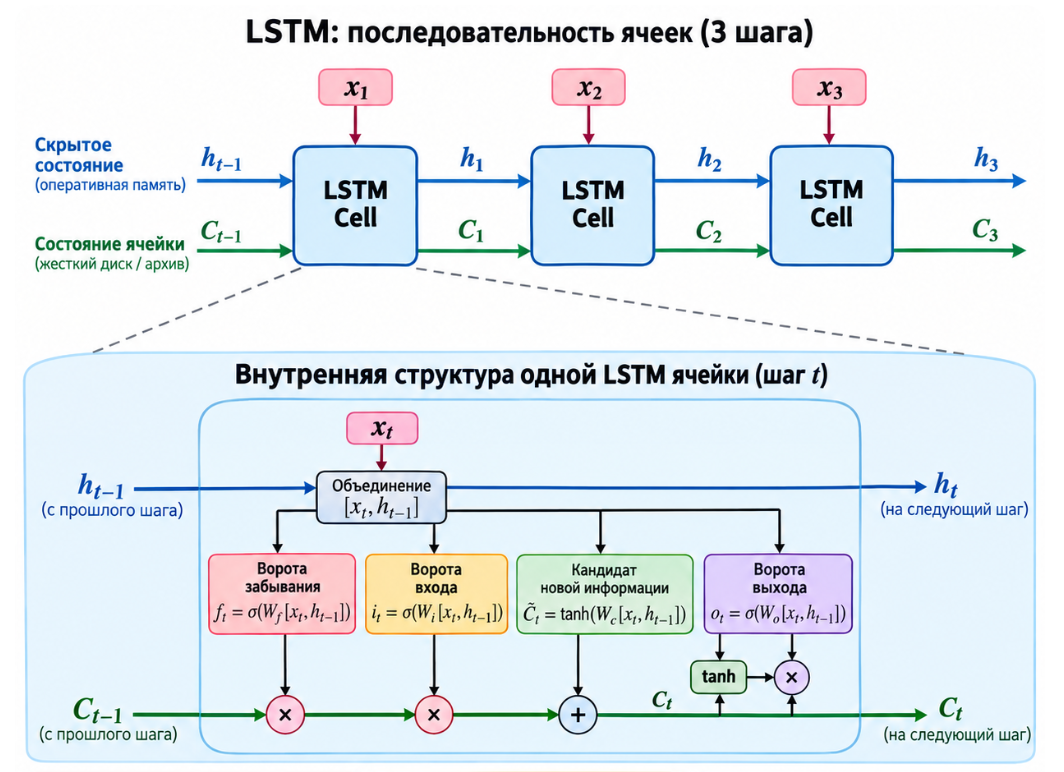

Входы $x_t$ и $h_{t-1}$ объединяются  в один вектор $[x_t, h_{t-1}]$. Этот объединенный вектор подается на все четыре компонента параллельно.\

1. Ворота забывания (Forget gate)\
$f_t = \sigma(W_f [x_t, h_{t-1}])$\
Сигмоида $\sigma$ выдает значения от 0 до 1\
*Решает, какую часть старой памяти $C_{t-1}$ нужно стереть*\
0 = полностью забыть, 1 = полностью сохранить\

2. Ворота входа (Input gate)\
$i_t = \sigma(W_i [x_t, h_{t-1}])$\
*Решает, насколько сильно обновлять память новой информацией*\
0 = не обновлять, 1 = полностью обновить\

3. Кандидат новой информации \
$\tilde{C}_t = \tanh(W_c [x_t, h_{t-1}])$\
$\tanh$ выдает значения от -1 до 1\
*Это "черновик" новой информации, которую можно записать в память*\

4. Ворота выхода (Output gate) — фиолетовый блок\
$o_t = \sigma(W_o [x_t, h_{t-1}])$\
*Решает, какую часть обновленной памяти $C_t$ выдать в качестве нового скрытого состояния $h_t$*\
\
\
**Происходит обновление состояния ячейки $C_t$ в 2 этапа**\
Забывание: $C_{t-1}$ умножается поэлементно на $f_t$. Если $f_t = 0$, информация стирается. Если $f_t = 1$, сохраняется.\
Добавление нового: Кандидат $\tilde{C}_t$ умножается поэлементно на $i_t$. Это отфильтрованная новая информация.\
Сложение: Результаты складываются ($+$):\
$C_t = f_t * C_{t-1} + i_t * \tilde{C}_t$\
\
\
Формирование нового скрытого состояния $h_t$: \
Состояние ячейки $C_t$ пропускается через $\tanh$\
Результат умножается поэлементно на ворота выхода $o_t$:\
$h_t = o_t * \tanh(C_t)$\
Это новое $h_t$ идет на следующий шаг и может использоваться как выход сети.


D. 
\
**Ванильный RNN**

Механика: Единое скрытое состояние $h_t$, которое полностью перезаписывается на каждом шаге: $h_t = \tanh(W_{hh}h_{t-1} + W_{xh}x_t + b_h)$.
При этом возникает затухание или быстрый рост градиента при обратном распространении через время (BPTT). Также невозможно сохранять долгосрочные зависимости.\
Впоследствии это ведёт к тому, что простая рекуррентная сеть (RNN) не способна связать информацию, которая находится в начале, с информацией в конце.\
\
\
\
**LSTM (Long Short-Term Memory)**

Информация разделена на два параллельных потока - скрытое состояние $h_t$ (краткосрочная память) и состояние ячейки $C_t$ (долгосрочная память).\
Управление потоками через три гейта (решает, что оставить, а что забыть): входной ($i_t$ - что запомнить из новых данных), забывания ($f_t$ - что стереть из прошлых) и выходной ($o_t$ - что выдать за результат).\
*Преимущество*: Аддитивное обновление состояния ячейки $C_t$ решает проблему исчезающего градиента, позволяя градиенту находится долго без изменений.\
($C_t$) и  ($h_t$) требуют много памяти компьютера.
\
\
\
**GRU (Gated Recurrent Unit)**

Упрощенная версия LSTM. Есть только один вектор — **$h_t$**. Он одновременно служит и долгосрочным архивом, и краткосрочным выходом. Использует всего два гейта: сброса ($r_t$ - важно ли предыдущее положение сейчас) и обновления ($z_t$ - от 0 до 1, что выбросить, а что оставить).\
Меньше весовых матриц (быстрее обучение, меньше данных для переобучения). По производительности на большинстве задач догоняет LSTM.

## Начальная работа

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset

from collections import Counter
from sklearn.model_selection import StratifiedShuffleSplit
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

In [2]:
dataset = pd.read_csv("data/baby_names.csv", sep=';')

In [3]:
dataset

,latin,cyrillic,gender
0,John,Джон,boy
1,William,Уильям,boy
2,James,Джеймс,boy
3,Charles,Чарльз,boy
4,George,Джордж,boy
...,...,...,...
6775,Laylah,Лейла,girl
6776,Carleigh,Карли,girl
6777,Kenley,Кенли,girl
6778,Sloane,Слоан,girl


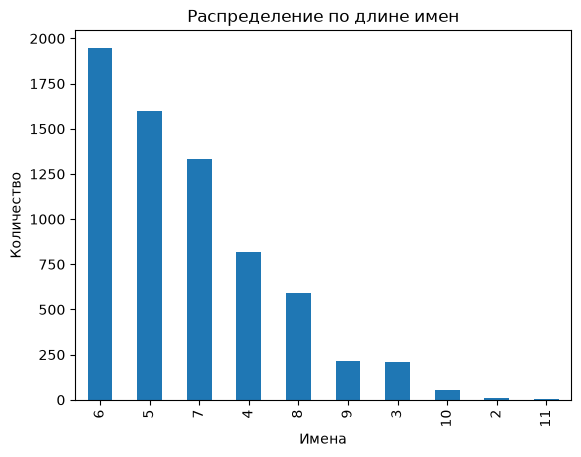

In [4]:
df_temp = dataset['latin'].str.len()
df_temp.value_counts().plot(kind='bar')
plt.title('Распределение по длине имен')
plt.xlabel('Имена')
plt.ylabel('Количество')
plt.show()

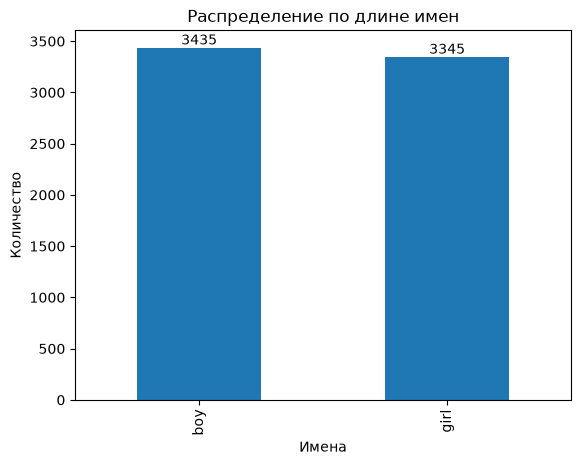

In [5]:
ax = dataset['gender'].value_counts().plot(kind='bar')
ax.bar_label(ax.containers[0])
plt.title('Распределение по длине имен')
plt.xlabel('Имена')
plt.ylabel('Количество')
plt.show()

In [6]:
# преобразую все строки к нижнему регистру
dataset['latin'] = dataset['latin'].str.lower()
dataset['cyrillic'] = dataset['cyrillic'].str.lower()

df = dataset.copy()

In [7]:
name_letters = Counter(''.join(df['latin'].dropna()))
name_letters.most_common(10)

[('a', 5592),
 ('e', 5037),
 ('n', 3519),
 ('i', 3264),
 ('l', 3255),
 ('r', 3070),
 ('o', 2070),
 ('t', 1745),
 ('s', 1674),
 ('d', 1531)]

## Подготовка данных

In [8]:
# кодирую пол
gender_name_dict = {'boy': 0, 'girl': 1}
df['gender'] = df['gender'].map(gender_name_dict)

In [9]:
symbol_latin = df['latin'].str.split('').explode().unique()

symbol_latin = sorted(symbol_latin[symbol_latin != ''])

fix = ['<', '>', ' ']
symbol_latin = fix + symbol_latin
print(symbol_latin)

['<', '>', ' ', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']


In [10]:
# словари переводчики
stoi = {char: idx for idx, char in enumerate(symbol_latin)}
itos = {idx: char for idx, char in enumerate(symbol_latin)}

In [11]:
# привожу все к 1 длине и добавляю префикс и постфикс, максимальная длина 13
max_len_latin = 11 + len('<') + len('>')

df['latin'] = df['latin'].map(lambda x: f'<{x}>'.ljust(max_len_latin))

In [12]:
# смотрю все ли строки преобразовались к нужной длине
df['latin'].str.len().value_counts()

latin
13    6780
Name: count, dtype: int64

In [13]:
df['latin'] = df['latin'].apply(lambda x: [stoi[char] for char in x])

In [14]:
df

,latin,cyrillic,gender
0,"[0, 12, 17, 10, 16, 1, 2, 2, 2, 2, 2, 2, 2]",джон,0
1,"[0, 25, 11, 14, 14, 11, 3, 15, 1, 2, 2, 2, 2]",уильям,0
2,"[0, 12, 3, 15, 7, 21, 1, 2, 2, 2, 2, 2, 2]",джеймс,0
3,"[0, 5, 10, 3, 20, 14, 7, 21, 1, 2, 2, 2, 2]",чарльз,0
4,"[0, 9, 7, 17, 20, 9, 7, 1, 2, 2, 2, 2, 2]",джордж,0
...,...,...,...
6775,"[0, 14, 3, 27, 14, 3, 10, 1, 2, 2, 2, 2, 2]",лейла,1
6776,"[0, 5, 3, 20, 14, 7, 11, 9, 10, 1, 2, 2, 2]",карли,1
6777,"[0, 13, 7, 16, 14, 7, 27, 1, 2, 2, 2, 2, 2]",кенли,1
6778,"[0, 21, 14, 17, 3, 16, 7, 1, 2, 2, 2, 2, 2]",слоан,1


In [15]:
X = df['latin'].values
y = df['gender'].values

In [16]:
# разделение набора данных
split = StratifiedShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
for train_idx, temp_idx in split.split(df, df['gender']):
    train_df = df.iloc[train_idx].reset_index(drop=True)
    temp_df  = df.iloc[temp_idx].reset_index(drop=True)

split = StratifiedShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
for val_idx, test_idx in split.split(temp_df, temp_df['gender']):
    val_df  = temp_df.iloc[val_idx].reset_index(drop=True)
    test_df = temp_df.iloc[test_idx].reset_index(drop=True)

### Создание датасета

In [17]:
class Data_set(Dataset):
    def __init__(self, df):
        self.sequences = df['latin'].tolist()
        self.genders = df['gender'].tolist()

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        x = torch.tensor(self.sequences[idx], dtype=torch.long)
        y = torch.tensor(self.genders[idx], dtype=torch.float32)
        return x, y


train_dataset = Data_set(train_df)
val_dataset = Data_set(val_df)
test_dataset = Data_set(test_df)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

## Рекуррентная нейронная сеть

### Реализация нейросети

In [32]:
# отдельный блок рнн
class VanillaRNN(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        # для входа
        self.W_xh = nn.Linear(input_size, hidden_size, bias=False)
        # для предыдущего скрытого состояния
        self.W_hh = nn.Linear(hidden_size, hidden_size, bias=False)
        self.bias = nn.Parameter(torch.zeros(hidden_size))

    def forward(self, x_t, h_prev):
        return torch.tanh(self.W_xh(x_t) + self.W_hh(h_prev) + self.bias)

In [33]:
class MY_RNNModel(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_size, dropout_prob=0.2):
        super().__init__()
        # Embedding превращает каждый индекс в обучаемый вектор 
        self.embedding = nn.Embedding(num_embeddings=vocab_size, embedding_dim=embed_dim)
        self.rnn_cell = VanillaRNN(input_size=embed_dim, hidden_size=hidden_size)
        
        # выключение части нейронов при обучении
        self.dropout = nn.Dropout(p=dropout_prob)
        # выход - сл символ
        self.token_output = nn.Linear(in_features=hidden_size, out_features=vocab_size)
        # выход - пол
        self.gender_output = nn.Linear(in_features=hidden_size, out_features=1)
        
        self.hidden_size = hidden_size
        
        # случайное начальное скрытое состояние
        self.h0 = nn.Parameter(torch.randn(hidden_size) * 0.01)

    # инициализация скрытого состояния
    def init_hidden(self, batch_size, device):
        return self.h0.repeat(batch_size, 1).to(device)

    def forward(self, x):
        batch_size, seq_len = x.shape
        device = x.device
        
        # 1. Применяем Embedding (п. 4.a.i)
        # На вход: индексы (batch_size, seq_len)
        # На выход: векторы (batch_size, seq_len, embed_dim)
        emb = self.embedding(x)
        
        h = self.init_hidden(batch_size, device)
        all_hidden_states = []
        
        for t in range(seq_len):
            # берет вектор символа
            h = self.rnn_cell(emb[:, t, :], h)
            all_hidden_states.append(h)
            
        # Склеиваем все скрытые состояния в один тензор
        # Форма: (batch_size, seq_len, hidden_size)
        all_hidden_states = torch.stack(all_hidden_states, dim=1)
        
        all_hidden_states = self.dropout(all_hidden_states)
        token_logits = self.token_output(all_hidden_states)

        # где закончить читать имя
        eos_mask = (x == 1)
        eos_positions = eos_mask.float().argmax(dim=1)
        last_hidden = all_hidden_states[torch.arange(batch_size), eos_positions]
        
        # вероятность пола по последнему предсказанию
        gender_logits = self.gender_output(last_hidden)
        
        return token_logits, gender_logits

In [33]:
def test_gender_auc(model, dataloader, device):
    model.eval()
    all_probs = []
    all_labels = []
    
    with torch.no_grad():
        for x_batch, y_batch in dataloader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            _, gender_logits = model(x_batch)

            gender_probs = torch.sigmoid(gender_logits)
            
            all_probs.append(gender_probs)
            all_labels.append(y_batch)
    # склеиваем все батчи в 1 размерный тензор        
    all_probs = torch.cat(all_probs).squeeze(1).cpu().numpy()
    all_labels = torch.cat(all_labels).cpu().numpy()
    
    return roc_auc_score(all_labels, all_probs)

### Обучение сети для буквы

In [18]:
def train_epoch(model, dataloader, optimizer, criterion, device, pad_idx):
    model.train()
    total_loss = 0
    
    bce_loss = nn.BCEWithLogitsLoss()
    for x_batch, y_batch in dataloader:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device).float()
        
        # обрезаем последний элемент
        x_input = x_batch[:, :-1]
        # правильные последующие символы
        x_target = x_batch[:, 1:]
        
        optimizer.zero_grad()
        
        # прямой проход
        token_logits, gender_prob = model(x_input)
        
        # вытягивание тензоров для CrossEntropyLoss
        logits_flat = token_logits.reshape(-1, token_logits.shape[-1])
        target_flat = x_target.reshape(-1)

        loss_tokens = criterion(logits_flat, target_flat)
        loss_gender = bce_loss(gender_prob.squeeze(-1), y_batch)
        loss = loss_tokens + loss_gender
        loss.backward()
        
        # ограничение градиентов
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        
        optimizer.step()
        total_loss += loss.item()
        
    return total_loss / len(dataloader)

В PyTorch функция nn.CrossEntropyLoss содержит внутри себя LogSoftmax, поэтому она не применялась в функции обучения для букв

In [19]:
def val_epoch(model, dataloader, criterion, device, pad_idx):
    model.eval()
    
    total_loss = 0.0
    num_batches = 0
    with torch.no_grad():
        bce_loss = nn.BCEWithLogitsLoss() 
        for x_batch, y_batch in dataloader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device).float()
            
            x_input = x_batch[:, :-1] 
            x_target = x_batch[:, 1:]   
            
            token_logits, gender_logits = model(x_input)
            
            logits_flat = token_logits.reshape(-1, token_logits.shape[-1])
            target_flat = x_target.reshape(-1)
            
            loss_tokens = criterion(logits_flat, target_flat)
            loss_gender = bce_loss(gender_logits.squeeze(-1), y_batch)
            loss = loss_tokens + loss_gender
            
            total_loss += loss.item() # достаём число
            num_batches += 1
            
    return total_loss / num_batches # среднее значение за эпоху

### Генерация имён

In [29]:
def generate_name(model, stoi, itos, start_token='<', end_token='>', temperature=1.0, max_len=20, device='cpu'):
    model.eval()

    start = stoi[start_token]
    generated = [start]

    with torch.no_grad():
        for _ in range(max_len):
            x = torch.tensor([generated], dtype=torch.long, device=device)

            # получение логитов
            token_logits, _ = model(x)
            # логиты для сл токена
            last_logits = token_logits[0, -1, :]

            scaled_logits = last_logits / temperature # самая вероятная буква получает почти 100% вкрятности
            # превращает логиты в вероятности
            probs = torch.softmax(scaled_logits, dim=-1)
            # выбмрает случайный индекс
            next_token = torch.multinomial(probs, num_samples=1).item()

            if next_token == stoi[end_token]:
                break

            generated.append(next_token)
    # добавление сгенерированного токена к последовательности
    name = ''.join([itos[idx] for idx in generated[1:]])
    return name

### Применение и оценка

In [129]:
vocab_size = len(stoi)
embed_dim = 32 # pазмер эмбеддинга
hidden_size = 64
dropout_prob = 0.2


model = MY_RNNModel(
    vocab_size=vocab_size,
    embed_dim=embed_dim,
    hidden_size=hidden_size,
    dropout_prob=dropout_prob
)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

pad_idx = symbol_latin.index(' ')
criterion = nn.CrossEntropyLoss(ignore_index=pad_idx) 

Epoch 5/25: Train Loss = 2.7102, Val Loss = 2.6380
Epoch 10/25: Train Loss = 2.6069, Val Loss = 2.5866
Epoch 15/25: Train Loss = 2.5449, Val Loss = 2.5484
Epoch 20/25: Train Loss = 2.5056, Val Loss = 2.5301
Epoch 25/25: Train Loss = 2.4591, Val Loss = 2.5270


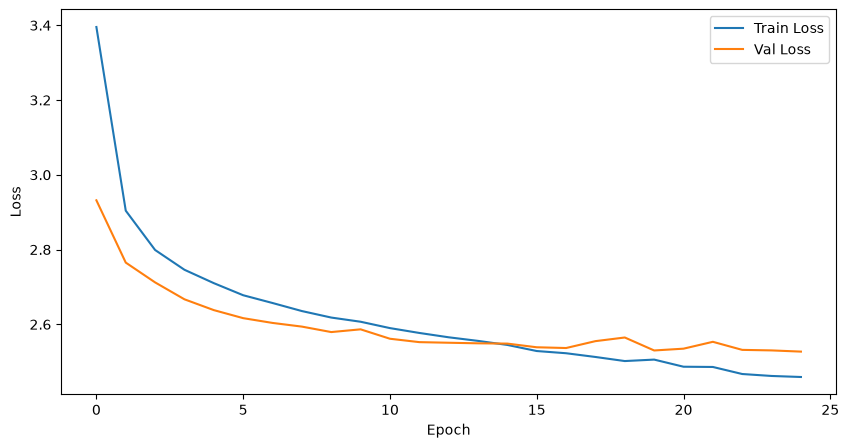

In [120]:
train_losses = []
valid_losses = []

for epoch in range(25):
    train_loss = train_epoch(model, train_loader, optimizer, criterion, device, pad_idx)
    valid_loss = val_epoch(model, val_loader, criterion, device, pad_idx)
    
    train_losses.append(train_loss)
    valid_losses.append(valid_loss)

    if (epoch + 1) % 5 == 0:
        print(f'Epoch {epoch+1}/25: Train Loss = {train_loss:.4f}, Val Loss = {valid_loss:.4f}')

plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Train Loss')
plt.plot(valid_losses, label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

#### Сгенерированные имена

In [92]:
for _ in range(10):
    print(generate_name(model, stoi, itos, temperature=0.8, device=device))

henilei
vina
annari
geeleney
aris
bilish
elvir
jurin
rana
elve


#### Предсказание пола

In [93]:
auc_score = test_gender_auc(model, test_loader, device)
print(f"ROC AUC на тестовых данных: {auc_score:.4f}")

ROC AUC на тестовых данных: 0.9068


## GRU

### Реализация модели

In [21]:
class GRU(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        
        self.W_z = nn.Linear(input_size + hidden_size, hidden_size, bias=True)
        self.W_r = nn.Linear(input_size + hidden_size, hidden_size, bias=True)
        self.W_h = nn.Linear(input_size + hidden_size, hidden_size, bias=True)
        
        self.hidden_size = hidden_size
    
    def forward(self, x_t, h_prev):
        # объкдиняяем вход и предыдущее скрытое состояние
        combined = torch.cat([x_t, h_prev], dim=-1) # (batch_size, input_size + hidden_size)
        
        # обновление
        z_t = torch.sigmoid(self.W_z(combined)) # (batch_size, hidden_size)
        # сброс
        r_t = torch.sigmoid(self.W_r(combined)) #(batch_size, hidden_size)
        
        # сколько останется старых 
        h_reset = r_t * h_prev # (batch_size, hidden_size)
        combined_reset = torch.cat([h_reset, x_t], dim=-1) # (batch_size, hidden_size + input_size)
        # вычисление нового выхода
        h_tilde = torch.tanh(self.W_h(combined_reset)) # (batch_size, hidden_size)
        
        # комбинация старого и нового
        h_next = (1 - z_t) * h_prev + z_t * h_tilde 
        return h_next

1. Update gate (z_t) — сколько старой памяти сохранить
2. Reset gate (r_t) — насколько игнорировать старую память при вычислении новой

$z_t = σ(W_z * [x_t, h_{t-1}] + b_z)$\
$r_t = σ(W_r * [x_t, h_{t-1}] + b_r)$\
$\tilde{h_t} = tanh(W_h * [r_t * h_{t-1}, x_t] + b_h)$\
$h_t = (1 - z_t) * h_{t-1} + z_t * \tilde{h_t}$

z_t = 0 → полностью сохранить старое h\
z_t = 1 → полностью заменить на новое $\tilde{h_t}$\
r_t = 0 → игнорировать старое h при вычислении кандидата\
r_t = 1 → использовать старое h полностью

In [22]:
class MY_GRUModel(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_size, dropout_prob=0.2):
        super().__init__()
        self.embedding = nn.Embedding(num_embeddings=vocab_size, embedding_dim=embed_dim)
        self.gru = GRU(input_size=embed_dim, hidden_size=hidden_size)
        
        # выключение части нейронов при обучении
        self.dropout = nn.Dropout(p=dropout_prob)
        # выход - следующий символ
        self.token_output = nn.Linear(in_features=hidden_size, out_features=vocab_size)
        # выход - пол
        self.gender_output = nn.Linear(in_features=hidden_size, out_features=1)
        
        self.hidden_size = hidden_size
        
        # случайное начальное скрытое состояние
        self.h0 = nn.Parameter(torch.randn(hidden_size) * 0.01)

    def init_hidden(self, batch_size, device):
        return self.h0.repeat(batch_size, 1).to(device)

    def forward(self, x):
        batch_size, seq_len = x.shape
        device = x.device
        
        emb = self.embedding(x)
        h = self.init_hidden(batch_size, device)
        all_hidden_states = []
        
        for t in range(seq_len):
            # берет вектор символа
            h = self.gru(emb[:, t, :], h)
            all_hidden_states.append(h)
            
        # все скрытые состояния в один тензор
        all_hidden_states = torch.stack(all_hidden_states, dim=1)
        all_hidden_states = self.dropout(all_hidden_states)
        token_logits = self.token_output(all_hidden_states)

        # где закончить читать имя
        eos_mask = (x == 1)
        eos_positions = eos_mask.float().argmax(dim=1)
        last_hidden = all_hidden_states[torch.arange(batch_size), eos_positions]
        
        # вероятность пола по последнему предсказанию
        gender_logits = self.gender_output(last_hidden)
        
        return token_logits, gender_logits

### Оценка

In [130]:
model_gru = MY_GRUModel(
    vocab_size=vocab_size,
    embed_dim=embed_dim,
    hidden_size=hidden_size,
    dropout_prob=dropout_prob
)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_gru = model_gru.to(device)

optimizer_gpu = torch.optim.Adam(model_gru.parameters(), lr=0.001)
pad_idx = symbol_latin.index(' ')
criterion_gpu = nn.CrossEntropyLoss(ignore_index=pad_idx)

In [122]:
train_losses_gru = []
valid_losses_gru = []

for epoch in range(25):
    train_loss = train_epoch(model_gru, train_loader, optimizer_gpu, criterion_gpu, device, pad_idx)
    valid_loss = val_epoch(model_gru, val_loader, criterion_gpu, device, pad_idx)
    
    train_losses_gru.append(train_loss)
    valid_losses_gru.append(valid_loss)
    
    if (epoch + 1) % 5 == 0:
        print(f'Epoch {epoch+1}/25: Train Loss = {train_loss:.4f}, Val Loss = {valid_loss:.4f}')

Epoch 5/25: Train Loss = 2.6839, Val Loss = 2.6031
Epoch 10/25: Train Loss = 2.5559, Val Loss = 2.5226
Epoch 15/25: Train Loss = 2.4738, Val Loss = 2.4617
Epoch 20/25: Train Loss = 2.3939, Val Loss = 2.4658
Epoch 25/25: Train Loss = 2.3260, Val Loss = 2.4844


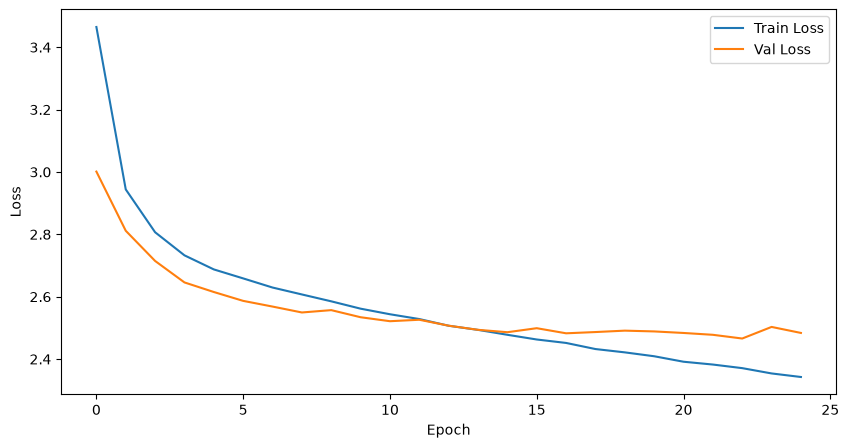

In [32]:
plt.figure(figsize=(10, 5))
plt.plot(train_losses_gru, label='Train Loss')
plt.plot(valid_losses_gru, label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [33]:
auc_gru = test_gender_auc(model_gru, test_loader, device)
print(f"ROC AUC на тестовых данных: {auc_gru:.4f}")

ROC AUC на тестовых данных: 0.9272


## LSTM

### Реализация LSTM

In [82]:
class LSTM(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        # что забыть из старой памяти
        self.W_f = nn.Linear(input_size + hidden_size, hidden_size, bias=True)
        # какую новую информацию добавить
        self.W_i = nn.Linear(input_size + hidden_size, hidden_size, bias=True)
        # новое состояние c
        self.W_c = nn.Linear(input_size + hidden_size, hidden_size, bias=True)
        # что выдать за ответ
        self.W_o = nn.Linear(input_size + hidden_size, hidden_size, bias=True)
        
        self.hidden_size = hidden_size

    def forward(self, x_t, h_prev, c_prev):
        combined = torch.cat([x_t, h_prev], dim=-1)
        
        f_t = torch.sigmoid(self.W_f(combined))
        i_t = torch.sigmoid(self.W_i(combined))
        c_tilde = torch.tanh(self.W_c(combined))
        o_t = torch.sigmoid(self.W_o(combined))
        
        # забываем старое + добавляем новое
        c_next = f_t * c_prev + i_t * c_tilde
        # новое скрытое состояние
        h_next = o_t * torch.tanh(c_next)
        
        return h_next, c_next

У LSTM два состояния:
c_t — cell state (долговременная память)\
h_t — hidden state (кратковременный выход)\
Три вентиля управляют ими: forget, input, output

#### Формулы

1. Forget gate ($f_t$) — что забыть из $c_{t-1}$\
$
f_t = \sigma(W_f \cdot [x_t, h_{t-1}] + b_f)
$
2. Input gate ($i_t$) — что добавить нового\
$
i_t = \sigma(W_i \cdot [x_t, h_{t-1}] + b_i)
$
3. Cell candidate ($\tilde{c}_t$) — каким может быть новое $c$\
$
\tilde{c}_t = \tanh(W_c \cdot [x_t, h_{t-1}] + b_c)
$
4. Output gate ($o_t$) — что выдать как $h_t$\
$
o_t = \sigma(W_o \cdot [x_t, h_{t-1}] + b_o)
$
5. Обновление cell state\
$
c_t = f_t \odot c_{t-1} + i_t \odot \tilde{c}_t
$
6. Обновление hidden state\
$
h_t = o_t \odot \tanh(c_t)
$\
где $\odot$ — поэлементное умножение.

#### Смысл вентилей

**Forget gate $f_t$**

$f_t = 0$ → полностью забыть старое $c_{t-1}$  
$f_t = 1$ → полностью сохранить старое $c_{t-1}$

**Input gate $i_t$**

$i_t = 0$ → не добавлять новую информацию  
$i_t = 1$ → полностью добавить кандидата $\tilde{c}_t$

**Cell candidate $\tilde{c}_t$**

$\tanh$ даёт значения от -1 до 1 — можно и усилить, и ослабить память  
Это «сырое» значение, которое пройдёт фильтр через $i_t$

**Output gate $o_t$**

$o_t = 0$ → не показывать ничего наружу ($h_t \approx 0$)  
$o_t = 1$ → полностью показать сжатое $c_t$

In [83]:
class MY_LSTMModel(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_size, dropout_prob=0.2):
        super().__init__()
        self.embedding = nn.Embedding(num_embeddings=vocab_size, embedding_dim=embed_dim)
        self.lstm = LSTM(input_size=embed_dim, hidden_size=hidden_size)
        
        self.dropout = nn.Dropout(p=dropout_prob)
        self.token_output = nn.Linear(in_features=hidden_size, out_features=vocab_size)
        self.gender_output = nn.Linear(in_features=hidden_size, out_features=1)
        
        self.hidden_size = hidden_size
        
        # случайное начальное скрытое состояние и состояние ячейки (долгосрочная память)
        self.h0 = nn.Parameter(torch.randn(hidden_size) * 0.01)
        self.c0 = nn.Parameter(torch.randn(hidden_size) * 0.01)

    def init_hidden(self, batch_size, device):
        h0 = self.h0.repeat(batch_size, 1).to(device)
        c0 = self.c0.repeat(batch_size, 1).to(device)
        return h0, c0

    def forward(self, x):
        batch_size, seq_len = x.shape
        device = x.device
        
        emb = self.embedding(x)
        
        h, c = self.init_hidden(batch_size, device)
        all_hidden_states = []
        
        for t in range(seq_len):
            # берет вектор эмбеддинга каждого символа и прогоняет через lstm
            h, c = self.lstm(emb[:, t, :], h, c)
            all_hidden_states.append(h)
            
        # все скрытые состояния в один тензор
        all_hidden_states = torch.stack(all_hidden_states, dim=1)
        
        all_hidden_states = self.dropout(all_hidden_states)
        token_logits = self.token_output(all_hidden_states)

        eos_mask = (x == 1)
        eos_positions = eos_mask.float().argmax(dim=1)
        last_hidden = all_hidden_states[torch.arange(batch_size), eos_positions]
        
        gender_logits = self.gender_output(last_hidden)
        return token_logits, gender_logits

### Оценка

In [131]:
model_lstm = MY_LSTMModel(
    vocab_size=vocab_size,
    embed_dim=embed_dim,
    hidden_size=hidden_size,
    dropout_prob=dropout_prob
)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_lstm = model_lstm.to(device)


optimizer_lstm = torch.optim.Adam(model_lstm.parameters(), lr=0.001)
criterion_lstm = nn.CrossEntropyLoss(ignore_index=pad_idx)

Epoch 5/25: Train Loss = 2.7042, Val Loss = 2.6497
Epoch 10/25: Train Loss = 2.5803, Val Loss = 2.5441
Epoch 15/25: Train Loss = 2.4904, Val Loss = 2.4947
Epoch 20/25: Train Loss = 2.4200, Val Loss = 2.4847
Epoch 25/25: Train Loss = 2.3568, Val Loss = 2.4634


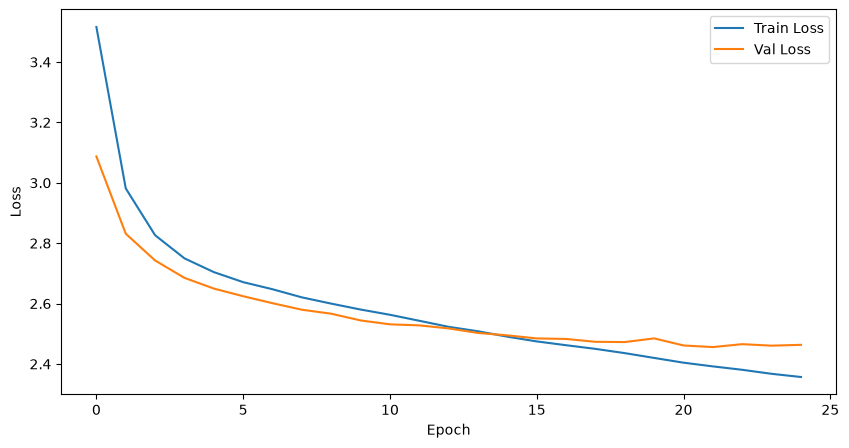

In [124]:
train_losses_lstm = []
valid_losses_lstm = []

for epoch in range(25):
    train_loss = train_epoch(model_lstm, train_loader, optimizer_lstm, criterion_lstm, device, pad_idx)
    valid_loss = val_epoch(model_lstm, val_loader, criterion_lstm, device, pad_idx)
    
    train_losses_lstm.append(train_loss)
    valid_losses_lstm.append(valid_loss)
    
    if (epoch + 1) % 5 == 0:
        print(f'Epoch {epoch+1}/25: Train Loss = {train_loss:.4f}, Val Loss = {valid_loss:.4f}')

plt.figure(figsize=(10, 5))
plt.plot(train_losses_lstm, label='Train Loss')
plt.plot(valid_losses_lstm, label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [77]:
auc_lstm = test_gender_auc(model_lstm, test_loader, device)
print(f"ROC AUC для классификации пола (LSTM): {auc_lstm:.4f}")

ROC AUC для классификации пола (LSTM): 0.9168


## Perplexity

Перплексия показывает насколько модель уверена в своем ответе. По сути она смотрит на количество вариантов между которыми выбирает нейронка.\
Если Perplexity = 1, то модель уверена в ответе. Чем больше, тем хуже.
\
\
$Perplexity=exp(CrossEntropyLoss)$\
\
$Perplexity = exp(\frac{-1}{N} \times sum(ln(P(y_i))))$\
, где $P(y_i)$ - вероятность, которую модель присвоила правильной букве

### Через torch.exp

In [46]:
def perplexity_with_ce(model, dataloader, criterion, device, pad_idx):
    model.eval()
    total_loss = 0.0
    num_batches = 0
    
    with torch.no_grad():
        for x_batch, y_batch in dataloader:
            x_batch = x_batch.to(device)
            
            x_input = x_batch[:, :-1]
            x_target = x_batch[:, 1:]
            
            # прямой проход
            token_logits, _ = model(x_input)
            logits_flat = token_logits.reshape(-1, token_logits.shape[-1])
            target_flat = x_target.reshape(-1)
            
            # содержит LogSoftmax
            loss = criterion(logits_flat, target_flat)
            
            total_loss += loss.item()
            num_batches += 1

    # среднее за эпоху
    avg_loss = total_loss / num_batches
    perplexity = math.exp(avg_loss)
    
    return perplexity

### Через вероятности

In [47]:
def perplexity_manual(model, dataloader, device, pad_idx):
    model.eval()
    # сумма логарифмов вероятностей
    total_log_prob = 0.0
    total_tokens = 0
    
    with torch.no_grad():
        for x_batch, y_batch in dataloader:
            x_batch = x_batch.to(device)
            
            x_input = x_batch[:, :-1] # все кроме последнего
            x_target = x_batch[:, 1:]
            
            token_logits, _ = model(x_input)
            # softmax для получения вероятностей
            probs = torch.softmax(token_logits, dim=-1)

            # маска для игнорирования пробелов
            mask = (x_target != pad_idx)
            
            batch_size, seq_len = x_target.shape
            # преобразование в 2д
            probs_flat = probs.reshape(-1, probs.shape[-1])
            target_flat = x_target.reshape(-1)
            mask_flat = mask.reshape(-1)
            
            # в-ть для правильного символа + маска без пробелов
            correct_probs = probs_flat.gather(1, target_flat.unsqueeze(1)).squeeze(1)
            correct_probs = correct_probs[mask_flat]
            
            log_probs = torch.log(correct_probs + 1e-10)
            total_log_prob += log_probs.sum().item()
            total_tokens += log_probs.shape[0]
    
    # средний логарифм вероятности
    avg_log_prob = total_log_prob / total_tokens
    perplexity = math.exp(-avg_log_prob)
    
    return perplexity

### Применение метрики

Для случайной модели baseline:\
$$P = \frac{1}{N}$$

$$\text{Perplexity} = \exp(-\ln(\frac{1}{P})) = \exp(\ln(N)) = P$$

Для случайной модели Перплексия равно количеству токенов - 29

#### Сравнение моделей по Перплексии

In [94]:
ppl_rnn_ce = perplexity_with_ce(model, test_loader, criterion, device, pad_idx)
ppl_rnn_manual = perplexity_manual(model, test_loader, device, pad_idx)
print(f"Vanilla RNN:")
print(f"Рerplexity (через CE): {ppl_rnn_ce:.4f}")
print(f"Рerplexity: {ppl_rnn_manual:.4f}")

ppl_gru_ce = perplexity_with_ce(model_gru, test_loader, criterion_gpu, device, pad_idx)
ppl_gru_manual = perplexity_manual(model_gru, test_loader, device, pad_idx)
print(f"GRU:")
print(f"Рerplexity (через CE): {ppl_gru_ce:.4f}")
print(f"Рerplexity: {ppl_gru_manual:.4f}")

ppl_lstm_ce = perplexity_with_ce(model_lstm, test_loader, criterion_lstm, device, pad_idx)
ppl_lstm_manual = perplexity_manual(model_lstm, test_loader, device, pad_idx)
print(f"LSTM:")
print(f"Рerplexity (через CE): {ppl_lstm_ce:.4f}")
print(f"Рerplexity: {ppl_lstm_manual:.4f}")

Vanilla RNN:
Рerplexity (через CE): 8.3404
Рerplexity: 8.3221
GRU:
Рerplexity (через CE): 8.1480
Рerplexity: 8.1292
LSTM:
Рerplexity (через CE): 8.1705
Рerplexity: 8.1430


#### Для самых популярных букв

In [105]:
# токены без пробелов
all_tokens = []
for seq in train_df['latin']:
    for t in seq:
        if t != pad_idx:
            all_tokens.append(t)

# частотность
token_counts = Counter(all_tokens)
total_tokens_count = sum(token_counts.values())
vocab_size = len(stoi)

# вероятность
freq_probs = np.ones(vocab_size) * 1e-10
for token, count in token_counts.items():
    freq_probs[token] = count / total_tokens_count

# перплексия на тесте
total_log_prob = 0.0
total_evaluated_tokens = 0
pad_idx = 2

for seq in test_df['latin']:
    target_tokens = [t for t in seq[1:] if t != pad_idx]
    for true_token in target_tokens:
        total_log_prob += math.log(freq_probs[true_token])
        total_evaluated_tokens += 1

perplexity_freq = math.exp(-total_log_prob / total_evaluated_tokens)
print(f"Перплексия частотной модели: {perplexity_freq:.4f}")
print(f"Сумма вероятностей: {sum(freq_probs):.6f}")

Перплексия частотной модели: 19.4979
Сумма вероятностей: 1.000000


## Классификация по полу

### Binary Cross Entropy

In [107]:
def train_gender_bce(model, train_loader, val_loader, epochs=20, lr=0.001):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.BCEWithLogitsLoss()
    train_losses, val_losses = [], []

    for epoch in range(epochs):
        model.train()
        epoch_loss = 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device).float()
            optimizer.zero_grad()
            _, gender_logits = model(x)
            loss = criterion(gender_logits.squeeze(-1), y)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
        
        # валидация
        model.eval()
        val_loss = 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device).float()
                _, gender_logits = model(x)
                val_loss += criterion(gender_logits.squeeze(-1), y).item()
                
        train_losses.append(epoch_loss / len(train_loader))
        val_losses.append(val_loss / len(val_loader))
        
    return train_losses, val_losses

### Negative Log Likelihood

In [108]:
def train_gender_nll(model, train_loader, val_loader, epochs=20, lr=0.001):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.NLLLoss()
    train_losses, val_losses = [], []

    for epoch in range(epochs):
        model.train()
        epoch_loss = 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device).long()
            optimizer.zero_grad()
            _, gender_logits = model(x)
            
            # форма для NLL (Batch, 2) + LogSoftmax
            logits_2class = torch.cat([-gender_logits, gender_logits], dim=1)
            log_probs = F.log_softmax(logits_2class, dim=1)
            
            loss = criterion(log_probs, y)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
            
        # валидация
        model.eval()
        val_loss = 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device).long()
                _, gender_logits = model(x)
                logits_2class = torch.cat([-gender_logits, gender_logits], dim=1)
                log_probs = F.log_softmax(logits_2class, dim=1)
                val_loss += criterion(log_probs, y).item()
                
        train_losses.append(epoch_loss / len(train_loader))
        val_losses.append(val_loss / len(val_loader))
        
    return train_losses, val_losses

### Обучение

In [125]:
model_rnn = MY_RNNModel(vocab_size, embed_dim, hidden_size).to(device)
model_gru = MY_GRUModel(vocab_size, embed_dim, hidden_size).to(device)
model_lstm = MY_LSTMModel(vocab_size, embed_dim, hidden_size).to(device)

rnn_bce_t, rnn_bce_v = train_gender_bce(model_rnn, train_loader, val_loader)
gru_bce_t, gru_bce_v = train_gender_bce(model_gru, train_loader, val_loader)
lstm_bce_t, lstm_bce_v = train_gender_bce(model_lstm, train_loader, val_loader)

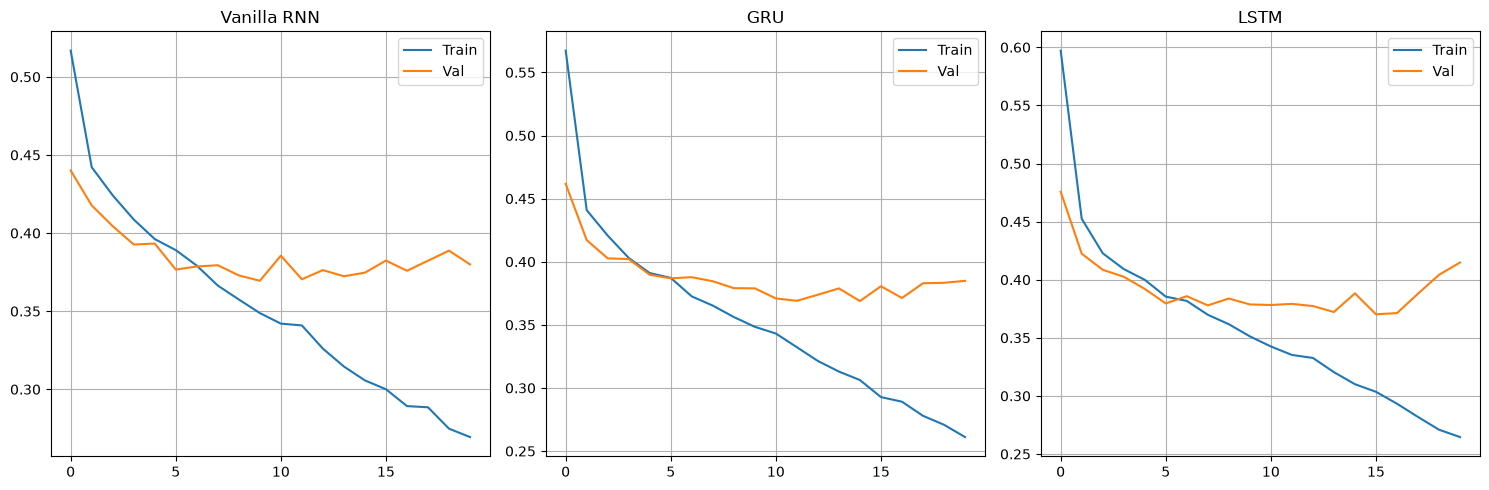

In [126]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.plot(rnn_bce_t, label='Train'); plt.plot(rnn_bce_v, label='Val')
plt.title('Vanilla RNN'); plt.legend(); plt.grid(True); plt.xticks(range(0, 20, 5))

plt.subplot(1, 3, 2)
plt.plot(gru_bce_t, label='Train'); plt.plot(gru_bce_v, label='Val')
plt.title('GRU'); plt.legend(); plt.grid(True); plt.xticks(range(0, 20, 5))

plt.subplot(1, 3, 3)
plt.plot(lstm_bce_t, label='Train'); plt.plot(lstm_bce_v, label='Val')
plt.title('LSTM'); plt.legend(); plt.grid(True); plt.xticks(range(0, 20, 5))

plt.tight_layout()
plt.show()

In [128]:
model_rnn = MY_RNNModel(vocab_size, embed_dim, hidden_size).to(device)
model_gru = MY_GRUModel(vocab_size, embed_dim, hidden_size).to(device)
model_lstm = MY_LSTMModel(vocab_size, embed_dim, hidden_size).to(device)

rnn_nll_t, rnn_nll_v = train_gender_nll(model_rnn, train_loader, val_loader)
gru_nll_t, gru_nll_v = train_gender_nll(model_gru, train_loader, val_loader)
lstm_nll_t, lstm_nll_v = train_gender_nll(model_lstm, train_loader, val_loader)

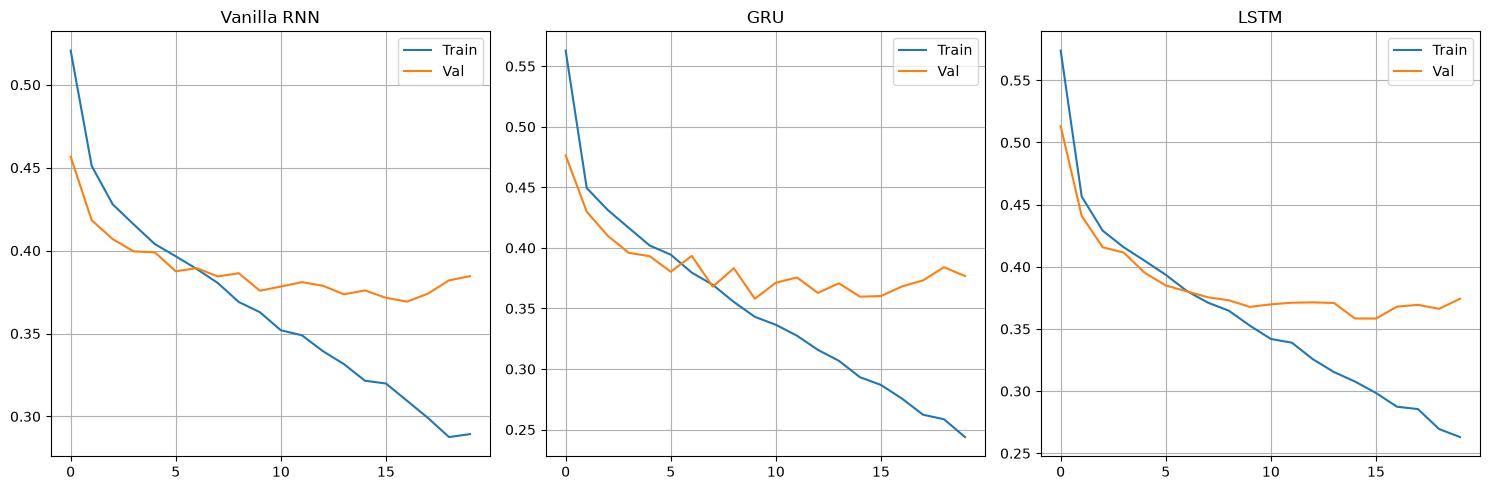

In [129]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.plot(rnn_nll_t, label='Train'); plt.plot(rnn_nll_v, label='Val')
plt.title('Vanilla RNN'); plt.legend(); plt.grid(True); plt.xticks(range(0, 20, 5))

plt.subplot(1, 3, 2)
plt.plot(gru_nll_t, label='Train'); plt.plot(gru_nll_v, label='Val')
plt.title('GRU'); plt.legend(); plt.grid(True); plt.xticks(range(0, 20, 5))

plt.subplot(1, 3, 3)
plt.plot(lstm_nll_t, label='Train'); plt.plot(lstm_nll_v, label='Val')
plt.title('LSTM'); plt.legend(); plt.grid(True); plt.xticks(range(0, 20, 5))

plt.tight_layout()
plt.show()

NLL предсказывает вероятность для правильного класса (Сеть выдает одно число на каждый пример)\
ВСЕ то же самое, но показывает среднее по всем примерам для 2 классов (Сеть выдает два числа на каждый пример (одно для класса 0, другое для класса 1))\
*Чем меньше метрики, тем лучше*

Так как они делают одно и то же, нрафики идентичны

Лучше взять ВСЕ. Он принимает только один логит и не требует доп обработки (в отлитчие от НЛЛ), также НЛЛ больше применим нде много классов.

In [116]:
print("Vanilla RNN:")
for _ in range(10): print(generate_name(model_rnn, stoi, itos, temperature=0.8, device=device))
print("\nGRU:")
for _ in range(10): print(generate_name(model_gru, stoi, itos, temperature=0.8, device=device))
print("\nLSTM:")
for _ in range(10): print(generate_name(model_lstm, stoi, itos, temperature=0.8, device=device))

Vanilla RNN:
cyicqbxzcwmj<sffawb 
sakxna
df<bdirdsrpn
kmfwyoss jxsm
phzcusdtgpxeayzvjahn
xhiflpgrdo<oj<qdsnjl
t sawuluprlxo<umkeo
f
<gvlip bgz<janxzmoln
ov< kvngiolzlvnguvij

GRU:
plq sdrssxinyawbxtck
kqtwzgi
xqcg<siqihjbiyreamek
hwiezhrftjllcsjixpjd
wkhcbuniyiqqzxnk
jwpmyhqcfghh vghjfan
<fufdtejkehfwrls lkh
hrnvtsfbhmiuswdhs< k
rowvtkkizjkyasikegsn
nuylugvmq

LSTM:
gll
vr xvnrkexksawbwpslf

awarbfw<
w lkbbkymaipyuzpotol
zsjbwi wtkesxdd<nuit
c<atpjaipncrxn<xpqxy

wteavssromwyv
hqiopvlsucbdmiwdfrve


Эти имена не реалистичны, так как модель обучалась только для пола (gender_logits)

In [117]:
print(f"Vanilla RNN ROC AUC: {test_gender_auc(model_rnn, test_loader, device):.4f}")
print(f"GRU ROC AUC: {test_gender_auc(model_gru, test_loader, device):.4f}")
print(f"LSTM ROC AUC: {test_gender_auc(model_lstm, test_loader, device):.4f}")

Vanilla RNN ROC AUC: 0.9036
GRU ROC AUC: 0.9123
LSTM ROC AUC: 0.9198


## Исчезающий градиент

### Подготовка данных

In [105]:
popular_lenght = dataset['latin'].str.len().mode()[0]
popular_lenght

np.int64(6)

In [106]:
df_popolar_lenght = pd.DataFrame(dataset[dataset['latin'].str.len() == popular_lenght])
df_popolar_lenght['latin'] = df_popolar_lenght['latin'].map(lambda x: f'<{x}>')

In [108]:
df_popolar_lenght['latin'] = df_popolar_lenght['latin'].apply(lambda x: [stoi[ch] for ch in x])
df_popolar_lenght['gender'] = df_popolar_lenght['gender'].map(gender_name_dict)

mode_dataset = TensorDataset(
    torch.tensor(df_popolar_lenght['latin'].values.tolist(), dtype=torch.long),
    torch.tensor(df_popolar_lenght['gender'].values, dtype=torch.float)
)
mode_loader = DataLoader(mode_dataset, batch_size=32, shuffle=True)
temp_mode_loader = DataLoader(mode_dataset, batch_size=1, shuffle=False)

### Функция сбора градиентов

In [116]:
class EmbeddingGradientCollector:
    def __init__(self, model):
        self.handle = None
        self.gradients = None

    # получаею градиент для каждой позиции каждого токена отдельно
    def _hook_fn(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach().cpu().clone()
        return None
    
    def register(self, model):
        self.handle = model.embedding.register_full_backward_hook(self._hook_fn)
    
    def remove(self):
        if self.handle:
            self.handle.remove()

def collect_gradients(model, dataloader, task='gender', n_epochs=5):
    model.train()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    collector = EmbeddingGradientCollector(model)
    
    vocab_size = model.embedding.num_embeddings
    embed_dim = model.embedding.embedding_dim
    
    # ширина первого батча
    seq_len = len(dataloader.dataset[0][0])
    
    all_grads = torch.zeros(n_epochs, seq_len, vocab_size, embed_dim)
    
    for epoch in range(n_epochs):
        for x_batch, y_batch in dataloader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device).float()
            optimizer.zero_grad()
            
            collector.register(model)
            token_logits, gender_logits = model(x_batch)
            
            if task == 'gender':
                loss = nn.BCEWithLogitsLoss()(gender_logits.squeeze(-1), y_batch)
            else:
                # для токенов
                x_in, x_out = x_batch[:, :-1], x_batch[:, 1:]
                logits_for_loss = token_logits[:, :-1, :]        # (B, 7, vocab)

                loss = nn.CrossEntropyLoss(ignore_index=2)(
                    logits_for_loss.reshape(-1, logits_for_loss.shape[-1]),
                    x_out.reshape(-1)
                )
            
            loss.backward()
            grad = collector.gradients  # (batch, seq_len, embed_dim)
            
            for i in range(x_batch.shape[0]):
                for pos in range(seq_len):
                    tok = x_batch[i, pos].item()
                    if tok != 2:
                        # кладнм градиент в нужную ячейку
                        all_grads[epoch, pos, tok] = grad[i, pos]
            # удаляю хук
            collector.remove()
            optimizer.step()
            
            if n_epochs == 1:
                break
    
    return all_grads

### Отладка

In [135]:
grads_debug = collect_gradients(model, temp_mode_loader, task='gender', n_epochs=1)
# норма каждого вектора по последнему измерению.
grad_norms = grads_debug.norm(dim=-1)

# сравнение с токенами из имени
x_sample = torch.tensor(df_popolar_lenght['latin'].values[:1].tolist())
print(f"Имя: {x_sample[0].tolist()}")
print("\nПозиция   Токен    Норма          Ненулевых в строке")
for pos in range(x_sample.shape[1]):
    tok = x_sample[0, pos].item()
    norm = grad_norms[0, pos, tok].item()
    nonzero = (grad_norms[0, pos] > 1e-10).sum().item()
    print(f"{pos:<8}   {tok:<6}   {norm:.6f}            {nonzero}")

Имя: [0, 9, 7, 17, 20, 9, 7, 1]

Позиция   Токен    Норма          Ненулевых в строке
0          0        0.035775            1
1          9        0.043607            1
2          7        0.082839            1
3          17       0.100078            1
4          20       0.128576            1
5          9        0.133190            1
6          7        0.198546            1
7          1        0.305566            1


Норма покажет, как сильно обновятся веса эмбеддинга для токена (чем больше норма, тем сильнее меняются веса)\
Из мини-таблицы видно, что для последнего токена норма не равна 0.

Происходит следующее:\
Модель читает имя , а потом идет обратно и на каждом шаге умножается на градиеты, которые меньше 0 и видно, что норма становится все меньше.

### Обучение моделей

In [137]:
n_epochs = 20

g_rnn = collect_gradients(model, mode_loader, 'gender', n_epochs)
g_gru = collect_gradients(model_gru, mode_loader, 'gender', n_epochs)
g_lstm = collect_gradients(model_lstm, mode_loader, 'gender', n_epochs)

f_rnn = g_rnn.norm(dim=(2,3)).mean(0).numpy()
f_gru = g_gru.norm(dim=(2,3)).mean(0).numpy()
f_lstm = g_lstm.norm(dim=(2,3)).mean(0).numpy()

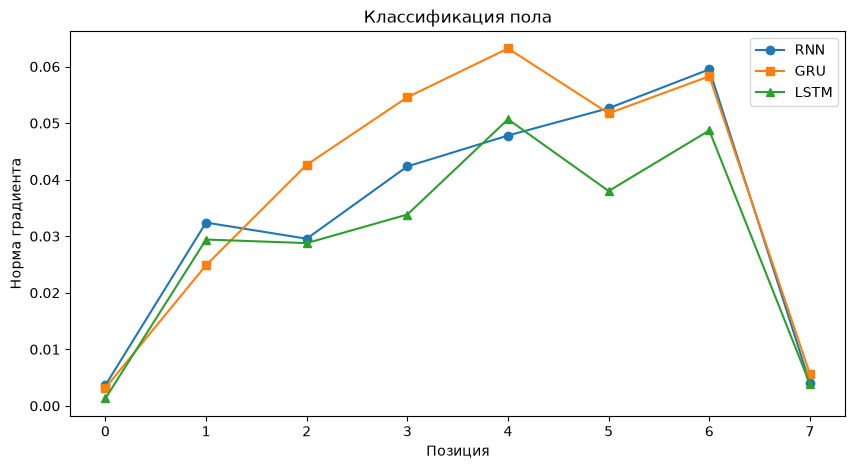

In [138]:
plt.figure(figsize=(10, 5))
plt.plot(f_rnn, 'o-', label='RNN')
plt.plot(f_gru, 's-', label='GRU')
plt.plot(f_lstm, '^-', label='LSTM')
plt.title('Классификация пола')
plt.xlabel('Позиция'); plt.ylabel('Норма градиента')
plt.legend()
plt.show()

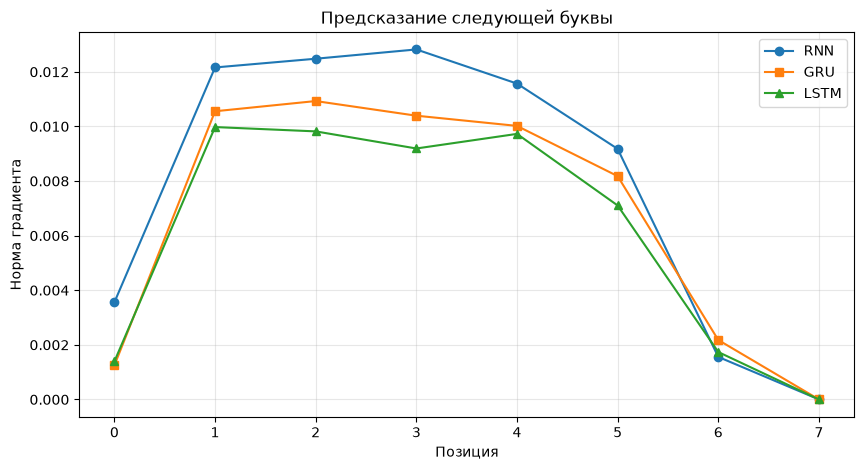

In [134]:
g_rnn_t = collect_gradients(model, mode_loader, 'token', n_epochs)
g_gru_t = collect_gradients(model_gru, mode_loader, 'token', n_epochs)
g_lstm_t = collect_gradients(model_lstm, mode_loader, 'token', n_epochs)

plt.figure(figsize=(10, 5))
plt.plot(g_rnn_t.norm(dim=(2,3)).mean(0).numpy(), 'o-', label='RNN')
plt.plot(g_gru_t.norm(dim=(2,3)).mean(0).numpy(), 's-', label='GRU')
plt.plot(g_lstm_t.norm(dim=(2,3)).mean(0).numpy(), '^-', label='LSTM')
plt.title('Предсказание следующей буквы')
plt.xlabel('Позиция'); plt.ylabel('Норма градиента')
plt.legend(); plt.grid(True, alpha=0.3)
plt.show()

Фиксированная длина нужна для корректного сравнения градиентов по позициям: иначе у коротких имен нет позиции 10, а паддинг искажает среднее значение\
На предсказаниях сл буквы веса меняются сильнее.

## Многозадачное обучение

In [35]:
model_multi = MY_GRUModel(
    vocab_size=len(stoi),
    embed_dim=64,
    hidden_size=128,
    dropout_prob=0.1
)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_multi = model_multi.to(device)

optimizer = torch.optim.Adam(model_multi.parameters(), lr=0.0001)
criterion = nn.CrossEntropyLoss(ignore_index=2)

train_losses = []
valid_losses = []

for epoch in range(40):
    train_loss = train_epoch(model_multi, train_loader, optimizer, criterion, device, pad_idx=2)
    valid_loss = val_epoch(model_multi, val_loader, criterion, device, pad_idx=2)
    
    train_losses.append(train_loss)
    valid_losses.append(valid_loss)
    
    if (epoch + 1) % 5 == 0:
        print(f'Epoch {epoch+1}/40: Train Loss = {train_loss:.4f}, Val Loss = {valid_loss:.4f}')

Epoch 5/40: Train Loss = 2.9798, Val Loss = 2.9109
Epoch 10/40: Train Loss = 2.7750, Val Loss = 2.7289
Epoch 15/40: Train Loss = 2.6862, Val Loss = 2.6483
Epoch 20/40: Train Loss = 2.6300, Val Loss = 2.5994
Epoch 25/40: Train Loss = 2.5905, Val Loss = 2.5642
Epoch 30/40: Train Loss = 2.5537, Val Loss = 2.5415
Epoch 35/40: Train Loss = 2.5207, Val Loss = 2.5211
Epoch 40/40: Train Loss = 2.4933, Val Loss = 2.5047


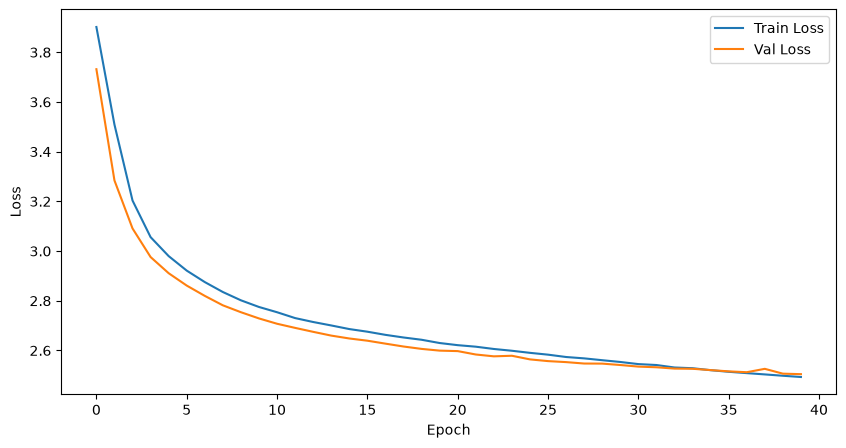

In [36]:
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Train Loss')
plt.plot(valid_losses, label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [37]:
# Сгенерированные 10 имён
for _ in range(10):
    print(generate_name(model_multi, stoi, itos, temperature=0.8, device=device))

lollina
huisa
lean
allan
levaro
kacie
sistavy
jerted
lissie
ederie


In [38]:
# Предсказание пола
auc_score = test_gender_auc(model_multi, test_loader, device)
print(f"ROC AUC на тестовых данных: {auc_score:.4f}")

ROC AUC на тестовых данных: 0.9203


!git add ml10.ipynb
!git commit -m "Многозадачное обу"
!git push origin develop